## Deep learning project : implementing a CNN transfer learning model for evaluating medical images  
   **Author:** *Xhovalin Panagiotis Qazimi | 02401,*
   **Dataset:** *kaggle, Diabetic Retinopathy | Sachin Kumar,*
   **Goal:** *The objective is to train a model capable of distinguishing healthy retinal images from retinal images affected by diabetic retinopathy*

### 1. Environment Setup & Data Acquisition

In this initial phase, we prepare our workspace and download the **Diabetic Retinopathy** dataset directly from Kaggle. 

### Key Actions:
* **Library Imports:** Loading essential tools for file system navigation and data handling.
* **Dataset Download:** Using `kagglehub` to fetch the latest version of the dataset.
* **Directory Exploration:** Mapping the file structure to understand the distribution of image classes.

> **Note:** We are using an API-based approach to ensure the project is reproducible and to handle the large volume of data efficiently without manual downloads.

In [3]:
import tensorflow as tf
import keras
from keras.models import Sequential
from tensorflow.keras import layers, models
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt 
import pandas as pd
import numpy as np 
import os 

In [4]:
import os
import kagglehub

path = kagglehub.dataset_download('sachinkumar413/diabetic-retinopathy-dataset')

data_dir = path 

print(os.listdir(data_dir))

c:\Users\User\miniconda3\envs\tf_directml\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['Healthy', 'Mild DR', 'Moderate DR', 'Proliferate DR', 'Severe DR']


count of images per category: {'Healthy': 1000, 'Mild DR': 370, 'Moderate DR': 900, 'Proliferate DR': 290, 'Severe DR': 190}


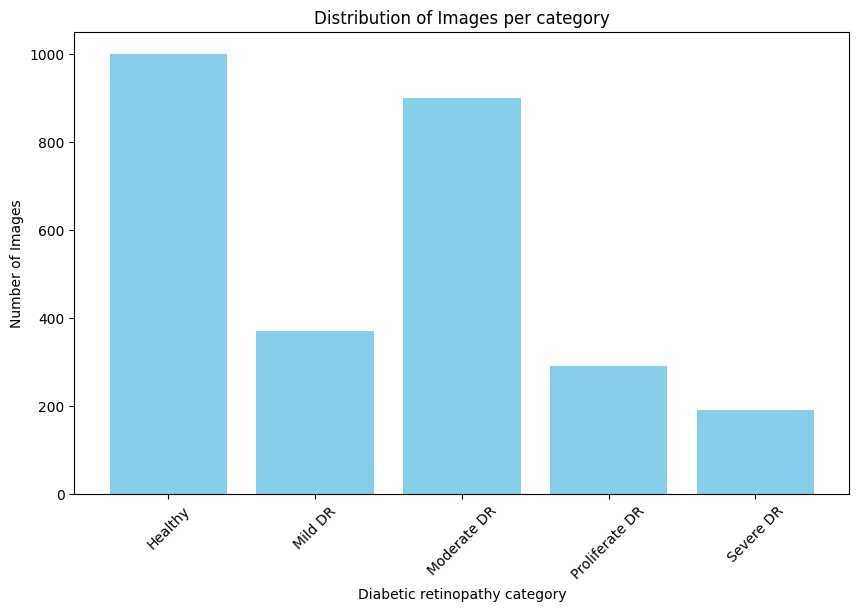

In [5]:
import matplotlib.pyplot as plt

# Get only the folders inside the dataset directory
categories = [f for f in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, f))]

# count the images per category 
counts = {}

# Loop through each category folder
for cat in categories:
    
    # Create the full path of the category folder
    cat_path = os.path.join(data_dir, cat)

    # Get all images/files inside this category
    images = [img for img in os.listdir(cat_path)]
    
    # Store the number of images for this category
    counts[cat] = len(images)

print("count of images per category:", counts)

plt.figure(figsize=(10,6))
plt.bar(counts.keys(), counts.values(), color='skyblue')
plt.xlabel('Diabetic retinopathy category')
plt.ylabel('Number of Images')
plt.title('Distribution of Images per category')
plt.xticks(rotation = 45)
plt.show()

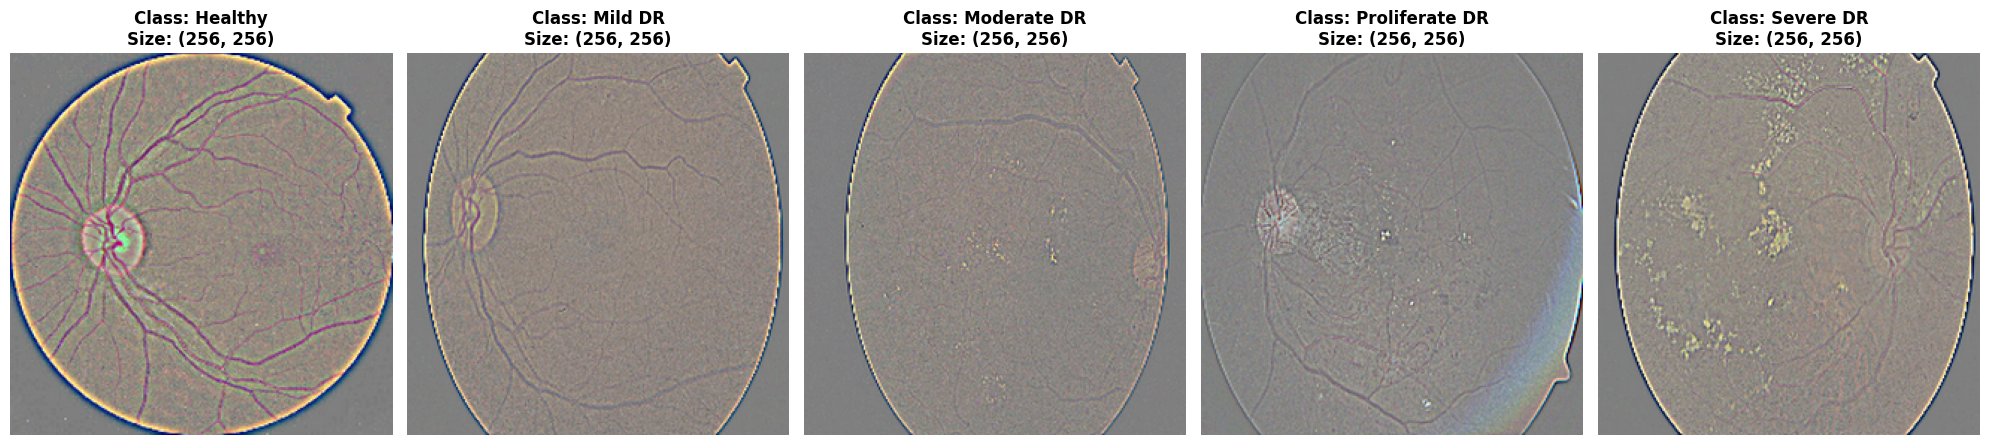

In [6]:
from PIL import Image # used for opening, displaying and editing images.

# Count how many categories exist
num_cats = len(categories)

# Create a large figure to show one image from each category
plt.figure(figsize=(20, 10)) 

# Loop through each category
for i, cat in enumerate(categories):
    
    # Create the full path of the current category folder
    cat_path = os.path.join(data_dir, cat)
    
    # Select the first image from this category
    img_name = os.listdir(cat_path)[0] 
    
    # Create the full path of the selected image
    img_path = os.path.join(cat_path, img_name)
    
    # Open the image using PIL
    img = Image.open(img_path)
    
    plt.subplot(1, num_cats, i + 1)
    plt.imshow(img)
    
    plt.title(f"Class: {cat}\nSize: {img.size}", fontsize=12, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [7]:
import shutil

# Store again the original dataset path
data_dir = path

# Create the binary dataset outside the original dataset folder
binary_dir = os.path.join(os.path.dirname(data_dir), "diabetic_retinopathy_binary")

# Create path for No_DR class
no_dr_dir = os.path.join(binary_dir, "No_DR")

# Create path for DR class
dr_dir = os.path.join(binary_dir, "DR")


# os.makedirs(no_dr_dir) # create N0_dr folder , now they are on comment section cause it already exists in the dir form the first run 
# os.makedirs(dr_dir)  #  create DR folder

# Define the healthy class from the original dataset
healthy_class = "Healthy"

# Define all diabetic retinopathy classes
dr_classes = [
    "Mild DR",
    "Moderate DR",
    "Proliferate DR",
    "Severe DR"
]

### Copying Healthy Images to the No_DR Folder

This code is used to reorganize the image dataset.

The original dataset contains a class called `Healthy`.  
In the binary classification version of the dataset, the `Healthy` images are copied into a new folder called `No_DR`.

This means that:

**Healthy → No_DR**

The code loops through every image inside the `Healthy` folder, creates the full source path of the image, creates the destination path inside the `No_DR` folder, and then copies the image.


In [8]:
# Healthy -> No_DR
for img in os.listdir(os.path.join(data_dir, healthy_class)):  # gets all image filenames from the Healthy folder
    src = os.path.join(data_dir, healthy_class, img) # is the original path of the image
    dst = os.path.join(no_dr_dir, img)  # is the new path where the image will be copied
    shutil.copy(src, dst) # copies the image from the original folder to the new folder


In [9]:
for cls in dr_classes:
    cls_path = os.path.join(data_dir, cls)

    for img in os.listdir(cls_path):
        src = os.path.join(cls_path, img)
        new_name = cls.replace(" ", "_") + "_" + img
        dst = os.path.join(dr_dir, new_name)
        shutil.copy(src, dst)

In [10]:
print("Binary dataset:")
print(os.listdir(binary_dir))
print("No_DR:", len(os.listdir(no_dr_dir)))
print("DR:", len(os.listdir(dr_dir)))

Binary dataset:
['DR', 'No_DR']
No_DR: 1000
DR: 1750


### Project Overview

This notebook focuses on binary classification of retinal fundus images for diabetic retinopathy detection.

The original dataset contains several classes, including `Healthy`, `Mild DR`, `Moderate DR`, `Severe DR`, and `Proliferate DR`. In this project, the dataset is reorganized into two main categories:

- `No_DR`: healthy images
- `DR`: images with diabetic retinopathy

Two deep learning models will be trained and compared:

1. A **Custom CNN** built from scratch.
2. A **MobileNetV2 transfer learning model** using pre-trained image features.

CLAHE preprocessing is also applied to improve image contrast and enhance important retinal structures. The models will be evaluated using accuracy, confusion matrix, and classification report.

In [11]:
import random
import cv2

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

In [12]:
IMG_SIZE = 224 # mobilenetV2 is trained wwith images 224x224 
BATCH_SIZE = 32 # how many images will be passed to the model each time during training
SEED = 42
EPOCHS = 20

# The seed value is set to 42 to make the random operations more reproducible.  
# The exact number is arbitrary; what matters is using the same seed throughout the experiment

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

### Creating a DataFrame with Image Paths and Labels

In this step, the image dataset is converted into a structured Pandas DataFrame.

The code loops through each class folder inside the binary dataset directory. For every image file, it stores:

- the full image file path
- the corresponding class label

Only image files with `.jpg`, `.jpeg`, or `.png` extensions are included.

The final DataFrame contains two columns:

- `filepaths`: the path of each image
- `labels`: the class name of each image

This format is useful because it allows the dataset to be easily split into training, validation, and test sets, and later loaded into image generators for model training.

In [13]:
filepaths = []
labels = []

for class_name in os.listdir(binary_dir):
    class_path = os.path.join(binary_dir, class_name)

    for img_name in os.listdir(class_path):
        if img_name.lower().endswith((".jpg", ".jpeg", ".png")):
            filepaths.append(os.path.join(class_path, img_name))
            labels.append(class_name)

df = pd.DataFrame({
    "filepaths": filepaths,
    "labels": labels
})

print(df.head())
print(df["labels"].value_counts())

                                           filepaths labels
0  C:\Users\User\.cache\kagglehub\datasets\sachin...     DR
1  C:\Users\User\.cache\kagglehub\datasets\sachin...     DR
2  C:\Users\User\.cache\kagglehub\datasets\sachin...     DR
3  C:\Users\User\.cache\kagglehub\datasets\sachin...     DR
4  C:\Users\User\.cache\kagglehub\datasets\sachin...     DR
labels
DR       1750
No_DR    1000
Name: count, dtype: int64


In [14]:
# ==========================================
# CLAHE PREPROCESSING FUNCTION
# ==========================================

def apply_clahe_rgb(img):
    
    # Convert image values to unsigned 8-bit integers.
    # OpenCV expects image pixels in the range 0-255 with uint8 format.
    img = img.astype(np.uint8)

    # Convert the image from RGB color space to LAB color space.
    # LAB separates brightness information from color information.
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)

    # Split the LAB image into its three channels:
    # L = lightness/brightness channel
    # A = green-red color channel
    # B = blue-yellow color channel

    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=2.0, # controls how much contrast enhancement is applied
        tileGridSize=(8, 8)  # defines the local regions where CLAHE is applied
    )
    
    # Apply CLAHE only to the L channel.
    # This enhances brightness/contrast without strongly changing the colors.
    l = clahe.apply(l)
    
    # Merge the enhanced L channel back with the original A and B channels.
    lab = cv2.merge((l, a, b))
    
    # Convert the image back from LAB color space to RGB.
    img = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    
    # Return the enhanced RGB image.
    return img

#### Effect of CLAHE Preprocessing

In this step, CLAHE preprocessing is applied to the retinal fundus images in order to improve local contrast.

By comparing the original images with the CLAHE-enhanced images, we can observe that important retinal structures become more visible. Blood vessels, texture patterns, and small bright lesion-like areas are enhanced after applying CLAHE. This can help the model detect visual differences between healthy and diabetic retinopathy images more effectively.

CLAHE is applied only to the brightness channel of the image, so the contrast is improved without strongly changing the original color information. This makes it useful for medical image preprocessing, where small details may be important for classification.

Overall, CLAHE helps enhance image details and may improve the ability MobileNetV2 models to learn useful retinal features.


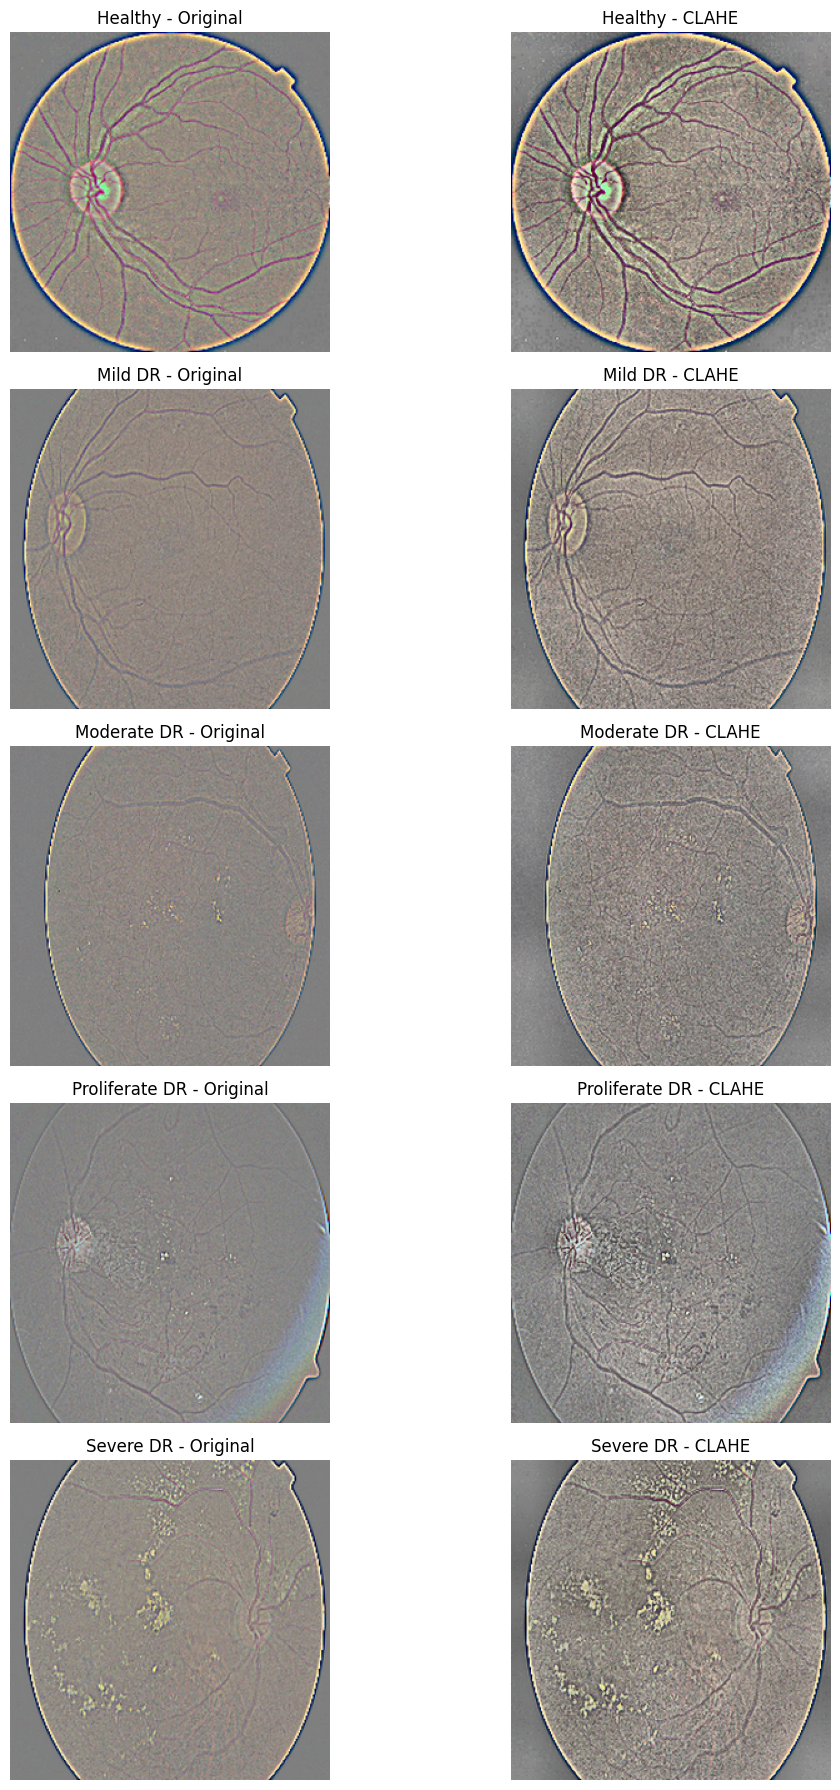

In [15]:
# ==========================================
# ORIGINAL VS CLAHE FOR ALL ORIGINAL CLASSES
# ==========================================

original_classes = [
    "Healthy",
    "Mild DR",
    "Moderate DR",
    "Proliferate DR",
    "Severe DR"
]

plt.figure(figsize=(12, 18))

for i, cls in enumerate(original_classes):

    cls_path = os.path.join(data_dir, cls)

    img_name = os.listdir(cls_path)[0]
    img_path = os.path.join(cls_path, img_name)

    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    img_clahe = apply_clahe_rgb(img_rgb)

    # Original image
    plt.subplot(len(original_classes), 2, 2*i + 1)
    plt.imshow(img_rgb)
    plt.title(f"{cls} - Original")
    plt.axis("off")

    # CLAHE image
    plt.subplot(len(original_classes), 2, 2*i + 2)
    plt.imshow(img_clahe)
    plt.title(f"{cls} - CLAHE")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Train, Validation, and Test Split

In this step, the dataset is divided into three separate parts:

- **Training set**: used to train the model.
- **Validation set**: used during training to monitor performance and tune the model.
- **Test set**: used only at the end to evaluate the final model on unseen data.

The first split assigns 70% of the data to the training set and keeps 30% as a temporary set.  
The temporary set is then split equally into validation and test sets.

This results in the following split:

- 70% training
- 15% validation
- 15% test

The `stratify` parameter is used to preserve the class distribution in all three sets. This means that the proportion of `DR` and `No_DR` images remains similar in the training, validation, and test datasets.

In [16]:
# ==========================================
# 6. TRAIN / VALIDATION / TEST SPLIT
# ==========================================

# First split:
# 70% of the dataset goes to training
# 30% is kept temporarily and will later be split into validation and test

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["labels"]
)

# Second split:
# The temporary 30% is split equally:
# 15% validation and 15% test
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["labels"] # the same proportion of classes is maintained in each set
)

# Print the number of images in each dataset split
print("Train:", len(train_df))
print("Validation:", len(valid_df))
print("Test:", len(test_df))

Train: 1925
Validation: 412
Test: 413


### Data Generators for MobileNetV2

In this step, data generators are created for the MobileNetV2 transfer learning model.

MobileNetV2 is a pre-trained convolutional neural network, so the input images must be preprocessed in the same way expected by the original model. For this reason, the `preprocess_input()` function from MobileNetV2 is used instead of simple rescaling.

Before applying MobileNetV2 preprocessing, CLAHE is applied to enhance local contrast in the retinal images. This helps highlight important retinal structures such as blood vessels and lesion-like regions.

For the training set, light data augmentation is also applied using small rotations, zooming, and horizontal flipping. This helps the model generalize better and reduces overfitting.

For the validation and test sets, no augmentation is applied. Only CLAHE and MobileNetV2 preprocessing are used, so the evaluation remains stable and realistic.

#### Why Data Generators Are Used

Data generators are used to load and preprocess images efficiently during model training.

Instead of loading the entire image dataset into memory at once, the generator loads a small batch of images at a time. This makes the training process more memory-efficient and suitable for larger image datasets.

In this project, the data generators perform several important steps:

- load images from their file paths
- resize all images to 224×224 pixels
- apply CLAHE preprocessing
- normalize pixel values
- apply data augmentation to the training images

Data augmentation is applied only to the training set. It creates slightly modified versions of the images, such as rotated, zoomed, or flipped images. This helps the model learn more robust features and reduces overfitting.

Validation and test generators do not use augmentation, because these datasets should be used to evaluate the model on stable and realistic unseen data.

In [17]:
# ==========================================
# DATA GENERATORS FOR MobileNetV2
# ==========================================

def clahe_mobilenet_preprocess(img):
    """
    Apply CLAHE preprocessing and then MobileNetV2-specific preprocessing.

    CLAHE improves the local contrast of the retinal image.
    preprocess_input prepares the image in the correct format expected by MobileNetV2.
    """

    # Apply CLAHE to enhance retinal contrast and details
    img = apply_clahe_rgb(img)

    # Apply MobileNetV2 preprocessing.
    # This transforms pixel values from the original 0-255 range
    # into the format expected by MobileNetV2, usually around -1 to 1.
    img = preprocess_input(img)

    # Return the processed image
    return img


# Generator for MobileNetV2 training data
# It applies CLAHE, MobileNetV2 preprocessing, and data augmentation.
train_datagen_mobile = ImageDataGenerator(
    
    # Apply CLAHE + MobileNetV2 preprocessing
    preprocessing_function=clahe_mobilenet_preprocess,
    
    # Randomly rotate training images up to 10 degrees
    rotation_range=10,
    
    # Randomly zoom training images slightly
    zoom_range=0.1,
    
    # Randomly flip training images horizontally
    horizontal_flip=True
)


# Generator for MobileNetV2 validation and test data
# No augmentation is applied here.
# Only CLAHE and MobileNetV2 preprocessing are used.
val_test_datagen_mobile = ImageDataGenerator(
    
    # Apply the same preprocessing used for MobileNetV2
    preprocessing_function=clahe_mobilenet_preprocess
)

In [18]:
# Create the MobileNetV2 training data generator
train_data_mobile = train_datagen_mobile.flow_from_dataframe(
    dataframe=train_df,       # DataFrame containing the training image paths and labels
    x_col="filepaths",           # Column containing the image file paths
    y_col="labels",               # Column containing the image labels
    target_size=(IMG_SIZE, IMG_SIZE),       # Resize all images to the input size expected by MobileNetV2
    batch_size=BATCH_SIZE,             # Number of images loaded per batch
    class_mode="binary",
    shuffle=True,
    seed=SEED
)

# Create the MobileNetV2 validation data generator
valid_data_mobile = val_test_datagen_mobile.flow_from_dataframe(
    
    dataframe=valid_df,           # DataFrame containing the validation image paths and labels
    x_col="filepaths",        # Column containing the image file paths
    y_col="labels",               # Column containing the image labels
    target_size=(IMG_SIZE, IMG_SIZE),       # Resize all images to the input size expected by MobileNetV2
    batch_size=BATCH_SIZE,             # Number of images loaded per batch
    class_mode="binary",
    shuffle=False
)

Found 1925 validated image filenames belonging to 2 classes.
Found 412 validated image filenames belonging to 2 classes.


In [19]:
# Create the MobileNetV2 test data generator
test_data_mobile = val_test_datagen_mobile.flow_from_dataframe(
    
    # DataFrame containing the test image paths and labels
    dataframe=test_df,
    
    # Column containing the image file paths
    x_col="filepaths",
    
    # Column containing the image labels
    y_col="labels",
    
    # Resize all test images to 224x224 pixels
    target_size=(IMG_SIZE, IMG_SIZE),
    
    # Number of images loaded per batch
    batch_size=BATCH_SIZE,
    
    # Binary classification: DR vs No_DR
    class_mode="binary",
    
    # Do not shuffle test data, so predictions match the true labels order
    shuffle=False
)

Found 413 validated image filenames belonging to 2 classes.


## Pretrained MobileNetV2 Model

In this section, a pretrained MobileNetV2 model is used for diabetic retinopathy classification.

MobileNetV2 is used as a transfer learning model. This means that the model has already been trained on a large image dataset called ImageNet and has learned useful visual features such as edges, shapes, textures, and patterns.

The parameter `weights="imagenet"` loads these pretrained weights. This helps the model start with already learned image features instead of learning everything from zero.

The parameter `include_top=False` removes the original final classification layers of MobileNetV2. These original layers were designed for ImageNet classification, which contains 1000 classes. Since this project is a binary classification task, a new custom classification head is added.

The base MobileNetV2 model is frozen using `base_model.trainable = False`. This means that the pretrained layers are not updated during training. MobileNetV2 is used only as a feature extractor, while the new layers added after it are trained for the specific task.

The custom classification head consists of:

- `GlobalAveragePooling2D`: converts the extracted feature maps into a compact feature vector.
- `Dense(128, activation="relu")`: learns task-specific patterns.
- `Dropout(0.5)`: helps reduce overfitting.
- `Dense(1, activation="sigmoid")`: produces the final binary prediction.

The final sigmoid output gives a probability between 0 and 1, which is used to classify the image as either `DR` or `No_DR`.

The model is compiled with the Adam optimizer and binary cross-entropy loss, which is suitable for binary classification problems.

In [20]:
# ==========================================
# 8B. PRETRAINED MobileNetV2 MODEL
# ==========================================

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False, # you only keep the feature extraction part.
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False # freeze the weights of pre-trained model  

mobilenet_model = models.Sequential([
    base_model, # MobileNetV2 without the final classification layer
    layers.GlobalAveragePooling2D(),  # It condenses all the image information into a vector of 1280 numbers.
    layers.Dense(128, activation="relu"), # a fully connencted layer with 128 neurons and ReLU activation to learn complex patterns from the extacted features 
    layers.Dropout(0.5), # remove the 50% of the neurons 
    layers.Dense(1, activation="sigmoid") 
])


base_model.summary()

mobilenet_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

Model: "mobilenetv2_1.00_224"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 224, 224, 3  0           []                               
                                )]                                                                
                                                                                                  
 Conv1 (Conv2D)                 (None, 112, 112, 32  864         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 bn_Conv1 (BatchNormalization)  (None, 112, 112, 32  128         ['Conv1[0][0]']                  
                                )                                              

In [ ]:
history_mobilenet = mobilenet_model.fit(
    train_data_mobile,
    validation_data=valid_data_mobile,
    epochs=EPOCHS
)

Epoch 1/20
61/61 [==============================] - 21s 295ms/step - loss: 0.3096 - accuracy: 0.8727 - val_loss: 0.2477 - val_accuracy: 0.9248
Epoch 2/20
61/61 [==============================] - 18s 296ms/step - loss: 0.1988 - accuracy: 0.9304 - val_loss: 0.1728 - val_accuracy: 0.9612
Epoch 3/20
61/61 [==============================] - 18s 291ms/step - loss: 0.1820 - accuracy: 0.9371 - val_loss: 0.1974 - val_accuracy: 0.9393
Epoch 4/20
61/61 [==============================] - 17s 276ms/step - loss: 0.1714 - accuracy: 0.9392 - val_loss: 0.1909 - val_accuracy: 0.9369
Epoch 5/20
61/61 [==============================] - 16s 269ms/step - loss: 0.1755 - accuracy: 0.9392 - val_loss: 0.1915 - val_accuracy: 0.9417
Epoch 6/20
61/61 [==============================] - 16s 260ms/step - loss: 0.1681 - accuracy: 0.9455 - val_loss: 0.1590 - val_accuracy: 0.9539
Epoch 7/20
61/61 [==============================] - 16s 264ms/step - loss: 0.1477 - accuracy: 0.9455 - val_loss: 0.1794 - val_accuracy: 0.9466

: 

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

: 

In [ ]:
def plot_training_history(history, model_name):

    # Convert accuracy to percentages
    train_acc = np.array(history.history["accuracy"]) * 100
    val_acc = np.array(history.history["val_accuracy"]) * 100

    # Accuracy plot
    plt.figure(figsize=(8, 5))

    plt.plot(train_acc, label="Train Accuracy")
    plt.plot(val_acc, label="Validation Accuracy")

    plt.title(f"{model_name} - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")

    # Percentage axis
    plt.yticks([80, 85, 90, 95, 100])
    plt.ylim(80, 100)

    plt.legend()
    plt.grid(True)
    plt.show()

    # Loss plot
    plt.figure(figsize=(8, 5))

    plt.plot(history.history["loss"], label="Train Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")

    plt.title(f"{model_name} - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    plt.legend()
    plt.grid(True)
    plt.show()

: 

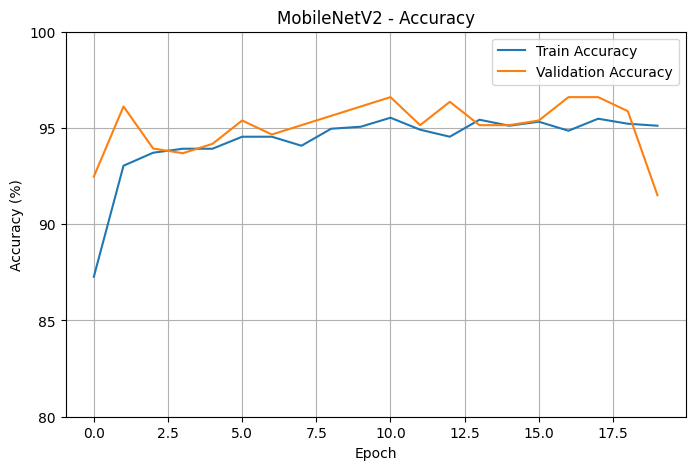

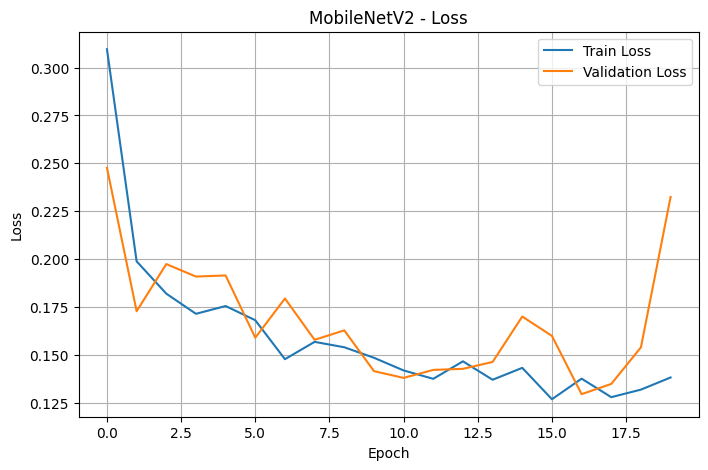

: 

In [ ]:
plot_training_history(history_mobilenet, "MobileNetV2")

## MobileNetV2 Evaluation: Confusion Matrix and Classification Report

In this section, the trained MobileNetV2 model is evaluated on the test set.

The test generator is first reset so that the predictions start from the first image and follow the same order as the true labels. This is important because the predicted labels must be aligned with the real labels when creating the confusion matrix.

The MobileNetV2 model predicts a probability for each test image. Since this is a binary classification task, the probabilities are converted into class predictions using a threshold of `0.5`:

* probability ≥ 0.5 → class `1`
* probability < 0.5 → class `0`

The true labels are obtained from the test generator, and the predicted labels are compared with them.

The confusion matrix shows how many images were correctly and incorrectly classified for each class. This helps identify whether the model confuses `DR` images with `No_DR` images, or the opposite.

The classification report provides additional evaluation metrics:

* **Precision**: how many images predicted as a class were actually correct
* **Recall**: how many real images of a class were correctly detected
* **F1-score**: the balance between precision and recall
* **Support**: the number of test images in each class

This evaluation is important because MobileNetV2 may achieve high accuracy, but the confusion matrix and classification report show whether the model performs well for both classes individually.


13/13 [==============================] - 2s 98ms/step
Class indices:
{'DR': 0, 'No_DR': 1}

Confusion Matrix:
[[228  35]
 [  0 150]]

Classification Report:
              precision    recall  f1-score   support

          DR       1.00      0.87      0.93       263
       No_DR       0.81      1.00      0.90       150

    accuracy                           0.92       413
   macro avg       0.91      0.93      0.91       413
weighted avg       0.93      0.92      0.92       413



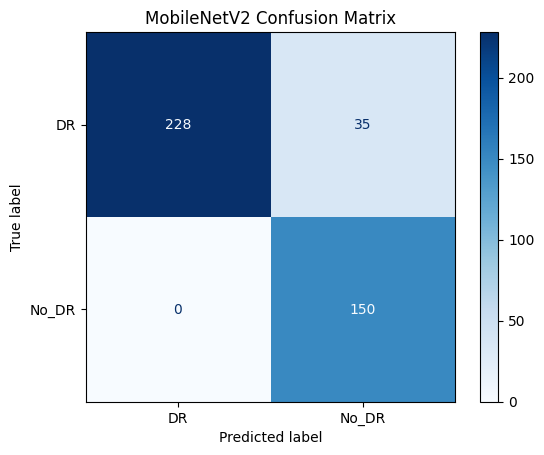

: 

In [ ]:
# ==========================================
# CONFUSION MATRIX FOR MobileNetV2
# ==========================================

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Reset the test generator to make sure predictions start from the first image
test_data_mobile.reset()

# Predict probabilities for the test images
y_pred_probs = mobilenet_model.predict(test_data_mobile)

# Convert probabilities to binary predictions
# If probability >= 0.5 -> class 1
# If probability < 0.5 -> class 0
y_pred = (y_pred_probs >= 0.5).astype(int).ravel()

# Get the true labels from the test generator
y_true = test_data_mobile.classes

# Get class names in the correct order
class_names = list(test_data_mobile.class_indices.keys())

# Create confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Print class mapping
print("Class indices:")
print(test_data_mobile.class_indices)

# Print confusion matrix
print("\nConfusion Matrix:")
print(cm)

# Print classification report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues")
plt.title("MobileNetV2 Confusion Matrix")
plt.show()

### Conclusion

MobileNetV2 was used as a pretrained transfer learning model for binary diabetic retinopathy classification. The pretrained base was frozen and used as a feature extractor, while only the final custom classification layers were trained for the `DR` and `No_DR` task.

CLAHE preprocessing was applied to enhance retinal image contrast, and `preprocess_input()` was used to prepare the images in the correct format expected by MobileNetV2.

The use of a frozen pretrained model reduced the number of trainable parameters, made training faster, and helped reduce the risk of overfitting. The final evaluation using the confusion matrix and classification report provided a more detailed view of the model’s performance for each class.

Overall, MobileNetV2 is an effective and efficient model for this task because it reuses strong pretrained visual features and adapts them to diabetic retinopathy detection.